<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 1 · Sesión 1: Ciclo de vida del crédito, originación y apetito de riesgo</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: embudo de originación, filtros, curva de estrategia, capacidad de pago y excepciones</div>
</div>

## Objetivos de la sesión (2 horas)

Al terminar este laboratorio podrás:

1. Recorrer el **ciclo de vida del crédito** (originación → seguimiento → cobranza → recuperación) con datos.
2. Medir el **embudo de originación**: solicitudes, filtros duros, decisión por score y capacidad de pago.
3. Construir la **curva de estrategia** (tasa de aprobación vs. tasa de malos) y usarla para traducir el **apetito de riesgo** en un punto de corte.
4. Cuantificar el efecto de una **política de capacidad de pago** (cuota/ingreso) y de las **excepciones**.

**Datos:** `hc_application_sintetico.csv`: 60 mil solicitudes con el esquema de *Home Credit Default Risk* (Kaggle). Es una muestra **sintética** con relaciones económicas plausibles: la tasa de incumplimiento ronda el 8 %, como en el original. `TARGET = 1` significa que el cliente incumplió (90+ días) en su ventana de desempeño.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 15 min | Carga y lectura del portafolio de solicitudes |
| 2 | 25 min | Embudo de originación y políticas de filtro |
| 3 | 30 min | Score, curva de estrategia y apetito de riesgo |
| 4 | 25 min | Capacidad de pago (RCI) y límites |
| 5 | 15 min | Excepciones y overrides |
| 6 | 10 min | Ejercicios y discusión |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

## 1. Carga y primera lectura de las solicitudes

In [2]:
app = pd.read_csv(DATA / "hc_application_sintetico.csv")
print(app.shape)
app.head()

(60060, 26)


,SK_ID_CURR,TARGET,FECHA_SOLICITUD,CANAL,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,...,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,OCCUPATION_TYPE,ORGANIZATION_TYPE,REGION_RATING_CLIENT,AMT_REQ_CREDIT_BUREAU_YEAR,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
0,110098,0,2025-10,Agencia,Cash loans,F,Y,Y,2,"18,800.0000",...,House / apartment,-15835,-1802,Sales staff,Business Entity Type 3,2,0,NaN,0.4975,NaN
1,115241,0,2024-04,Agencia,Cash loans,F,Y,Y,0,"43,000.0000",...,House / apartment,-14149,-964,Accountants,Bank,1,3,0.4679,0.4546,0.4467
2,103369,0,2022-02,Digital,Cash loans,M,N,Y,0,"57,800.0000",...,With parents,-18758,-1011,Sales staff,Bank,1,1,NaN,0.5622,0.3732
3,101226,0,2024-09,Digital,Cash loans,M,Y,Y,3,"70,400.0000",...,House / apartment,-18961,-551,Sales staff,Business Entity Type 3,2,1,NaN,0.7551,NaN
4,100672,0,2022-04,Digital,Cash loans,F,N,Y,0,"72,600.0000",...,House / apartment,-22065,365243,NaN,Self-employed,2,2,NaN,0.5253,0.3392


In [3]:
# Variables derivadas de negocio
app["EDAD"] = -app["DAYS_BIRTH"] / 365.25
app["ANTIG_LABORAL"] = np.where(app["DAYS_EMPLOYED"] == 365243, np.nan, -app["DAYS_EMPLOYED"] / 365.25)
app["RCI"] = app["AMT_ANNUITY"] / (app["AMT_INCOME_TOTAL"] / 12)      # relación cuota / ingreso mensual
app["LTI"] = app["AMT_CREDIT"] / app["AMT_INCOME_TOTAL"]              # préstamo / ingreso anual
app[["EDAD", "ANTIG_LABORAL", "RCI", "LTI", "TARGET"]].describe().T

,count,mean,std,min,25%,50%,75%,max
EDAD,"60,060.0000",45.1473,13.3928,20.9993,33.4531,45.9220,57.0486,68.9966
ANTIG_LABORAL,"49,357.0000",5.9615,4.4763,0.0082,2.7324,4.8761,8.0411,37.8919
RCI,"60,060.0000",0.3710,0.3513,0.0165,0.1535,0.2628,0.4583,6.1017
LTI,"60,060.0000",0.6211,0.4244,0.0526,0.3382,0.5044,0.7831,6.0282
TARGET,"60,060.0000",0.0798,0.2710,0.0000,0.0000,0.0000,0.0000,1.0000


> **Pregunta para la clase:** `DAYS_EMPLOYED = 365243` aparece en ~18 % de los registros. ¿Qué significa? ¿Qué pasaría si lo usáramos sin tratar?
> *(Pista: cruza con `NAME_INCOME_TYPE`.)*

In [4]:
pd.crosstab(app["DAYS_EMPLOYED"] == 365243, app["NAME_INCOME_TYPE"])

NAME_INCOME_TYPE,Commercial associate,Pensioner,State servant,Unemployed,Working
DAYS_EMPLOYED,,,,,
False,14033,0,4263,33,31028
True,0,10703,0,0,0


### Tasa de malos por segmento: la primera conversación con negocio
Antes de cualquier modelo, un equipo de riesgo mira **cómo cambia el riesgo** entre segmentos simples.

In [5]:
def tasa_malos(df, col):
    g = df.groupby(col)["TARGET"].agg(n="size", malos="sum", tasa_malos="mean")
    g["participacion"] = g["n"] / g["n"].sum()
    return g.sort_values("tasa_malos", ascending=False)

for c in ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "CANAL", "REGION_RATING_CLIENT"]:
    display(tasa_malos(app, c).style.format({"tasa_malos": "{:.2%}", "participacion": "{:.1%}"}))

,n,malos,tasa_malos,participacion
NAME_INCOME_TYPE,,,,
Working,31028,3065,9.88%,51.7%
Commercial associate,14033,1101,7.85%,23.4%
Unemployed,33,2,6.06%,0.1%
State servant,4263,244,5.72%,7.1%
Pensioner,10703,382,3.57%,17.8%


,n,malos,tasa_malos,participacion
NAME_EDUCATION_TYPE,,,,
Lower secondary,810,88,10.86%,1.3%
Secondary / secondary special,42644,3803,8.92%,71.0%
Incomplete higher,1958,136,6.95%,3.3%
Academic degree,19,1,5.26%,0.0%
Higher education,14629,766,5.24%,24.4%


,n,malos,tasa_malos,participacion
CANAL,,,,
Retail aliado,7111,670,9.42%,11.8%
Digital,14938,1302,8.72%,24.9%
Fuerza de ventas,10835,807,7.45%,18.0%
Agencia,27176,2015,7.41%,45.2%


,n,malos,tasa_malos,participacion
REGION_RATING_CLIENT,,,,
3,9432,993,10.53%,15.7%
2,44437,3437,7.73%,74.0%
1,6191,364,5.88%,10.3%


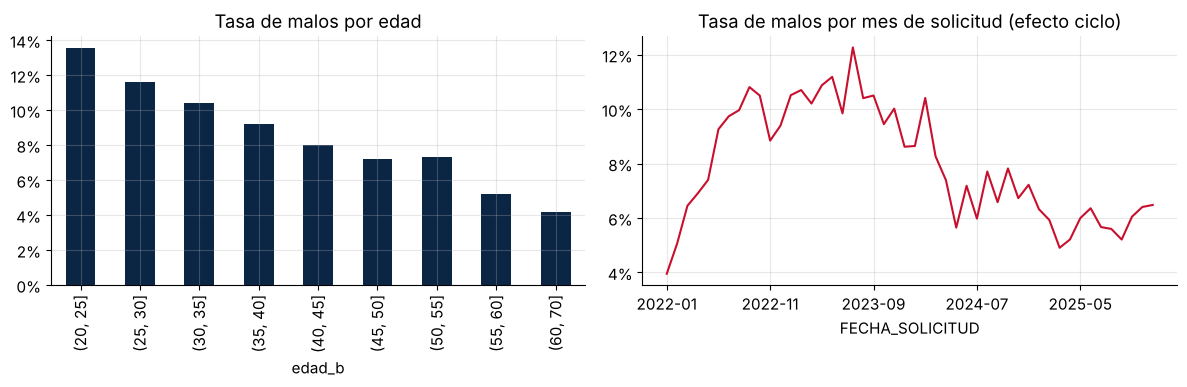

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
app.assign(edad_b=pd.cut(app.EDAD, [20, 25, 30, 35, 40, 45, 50, 55, 60, 70])).groupby("edad_b", observed=True)["TARGET"].mean().plot(kind="bar", ax=ax[0], color=AZUL)
ax[0].set_title("Tasa de malos por edad"); ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
app.groupby("FECHA_SOLICITUD")["TARGET"].mean().plot(ax=ax[1], color=ROJO)
ax[1].set_title("Tasa de malos por mes de solicitud (efecto ciclo)"); ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.tight_layout(); plt.show()

**Lectura:** el riesgo **no es estable en el tiempo**. Las cosechas originadas en 2022-2023 (inflación alta, tasas altas y desaceleración) muestran más incumplimiento que las de 2025. Esta idea vuelve en los módulos de PD *point-in-time* vs. *through-the-cycle* (Módulo 7) y de *stress testing* (Módulo 9).

## 2. Embudo de originación y filtros duros (*knock-out rules*)

Una política de admisión típica de banca minorista tiene capas:

1. **Filtros duros:** edad, ingreso mínimo, calificación en la central de riesgos (RCC SBS), listas negras, fraude.
2. **Score:** probabilidad de incumplimiento estimada → banda de riesgo.
3. **Capacidad de pago:** RCI (cuota/ingreso), endeudamiento total, LTI.
4. **Asignación de línea/monto y precio.**
5. **Excepciones:** aprobaciones fuera de política con autonomía definida.

Simulemos los filtros duros:

In [7]:
FILTROS = {
    "Edad entre 21 y 70": (app.EDAD >= 21) & (app.EDAD <= 70),
    "Ingreso anual >= S/ 18 mil": app.AMT_INCOME_TOTAL >= 18_000,
    "No desempleado": app.NAME_INCOME_TYPE != "Unemployed",
    "Consultas buró último año <= 6": app.AMT_REQ_CREDIT_BUREAU_YEAR <= 6,
}
mask = pd.Series(True, index=app.index)
embudo = [("Solicitudes", len(app), app.TARGET.mean())]
for nombre, cond in FILTROS.items():
    mask &= cond
    embudo.append((nombre, mask.sum(), app.loc[mask, "TARGET"].mean()))
embudo = pd.DataFrame(embudo, columns=["etapa", "n", "tasa_malos"])
embudo["pct_sobre_solicitudes"] = embudo.n / embudo.n.iloc[0]
embudo.style.format({"tasa_malos": "{:.2%}", "pct_sobre_solicitudes": "{:.1%}", "n": "{:,}"})

,etapa,n,tasa_malos,pct_sobre_solicitudes
0,Solicitudes,"60,060",7.98%,100.0%
1,Edad entre 21 y 70,"60,057",7.98%,100.0%
2,Ingreso anual >= S/ 18 mil,"57,822",8.00%,96.3%
3,No desempleado,"57,789",8.00%,96.2%
4,Consultas buró último año <= 6,"57,565",7.99%,95.8%


In [8]:
# ¿Qué tan "malos" son los rechazados por cada filtro (aislado)?
res = []
for nombre, cond in FILTROS.items():
    rech = ~cond
    res.append((nombre, rech.sum(), app.loc[rech, "TARGET"].mean() if rech.sum() else np.nan))
pd.DataFrame(res, columns=["filtro", "rechazados", "tasa_malos_rechazados"]).style.format({"tasa_malos_rechazados": "{:.2%}"})

,filtro,rechazados,tasa_malos_rechazados
0,Edad entre 21 y 70,3,0.00%
1,Ingreso anual >= S/ 18 mil,2235,7.56%
2,No desempleado,33,6.06%
3,Consultas buró último año <= 6,229,10.04%


> **Discusión:** un filtro que rechaza clientes cuya tasa de malos es parecida al promedio **destruye volumen sin reducir riesgo**. ¿Qué filtro justificarías ante el comité y cuál revisarías?

## 3. Score, curva de estrategia y apetito de riesgo

Aún no tenemos un modelo propio (lo construiremos en el Módulo 3). Usaremos un **score de buró simulado** que combina `EXT_SOURCE_1..3`: es un *proxy* de lo que hace un score genérico de buró.

In [9]:
ext = app[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]]
app["SCORE_BURO"] = (ext.mean(axis=1).fillna(ext.mean(axis=1).median()) * 1000).round()   # escala 0-1000: más alto, menos riesgo
from sklearn.metrics import roc_auc_score
print("AUC del score de buró:", round(roc_auc_score(app.TARGET, -app.SCORE_BURO), 3))

app["BANDA"] = pd.qcut(app.SCORE_BURO, 10, labels=[f"D{i}" for i in range(1, 11)])   # D1 = más riesgoso
tabla_bandas = app.groupby("BANDA", observed=True).agg(score_min=("SCORE_BURO", "min"), score_max=("SCORE_BURO", "max"),
                                                       n=("TARGET", "size"), tasa_malos=("TARGET", "mean"))
tabla_bandas.style.format({"tasa_malos": "{:.2%}"}).bar(subset=["tasa_malos"], color="#f4a3a8")

AUC del score de buró: 0.734


,score_min,score_max,n,tasa_malos
BANDA,,,,
D1,33.000000,324.000000,6052,24.70%
D2,325.000000,400.000000,6053,13.60%
D3,401.000000,458.000000,5965,9.81%
D4,459.000000,509.000000,6095,8.42%
D5,510.000000,556.000000,5901,6.41%
D6,557.000000,603.000000,6014,5.04%
D7,604.000000,651.000000,6004,4.78%
D8,652.000000,704.000000,5994,3.34%
D9,705.000000,771.000000,5996,2.20%


### Curva de estrategia (*strategy curve*)
Para cada punto de corte calculamos la **tasa de aprobación** y la **tasa de malos de los aprobados**. El **apetito de riesgo** fija un máximo de tasa de malos (o de pérdida esperada). La política escoge el corte que **maximiza la aprobación** sin pasar ese máximo.

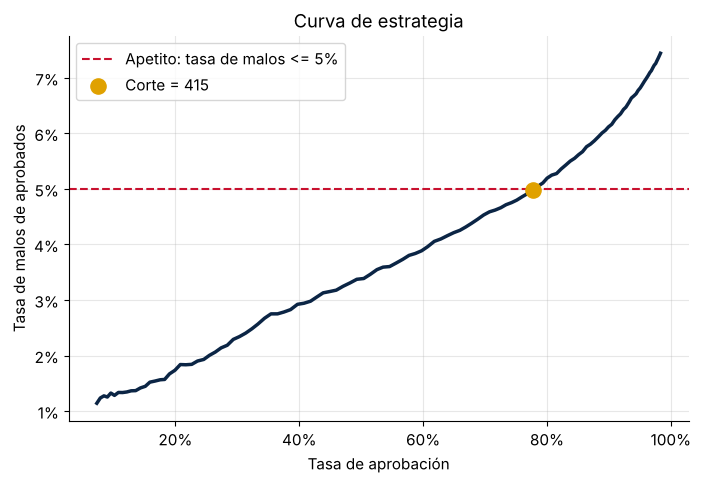

Corte 415: aprobación 77.7%, tasa de malos 4.99%


In [10]:
base = app[mask].copy()          # sobre los que pasaron filtros duros
cortes = np.arange(200, 800, 5)
curva = pd.DataFrame([(c, (base.SCORE_BURO >= c).mean(), base.loc[base.SCORE_BURO >= c, "TARGET"].mean()) for c in cortes],
                     columns=["corte", "tasa_aprobacion", "tasa_malos"])

APETITO = 0.05     # máxima tasa de malos aceptada en la cosecha
corte_opt = curva.loc[curva.tasa_malos <= APETITO, "corte"].min()
fila = curva[curva.corte == corte_opt].iloc[0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(curva.tasa_aprobacion, curva.tasa_malos, color=AZUL, lw=2.5)
ax.axhline(APETITO, color=ROJO, ls="--", label=f"Apetito: tasa de malos <= {APETITO:.0%}")
ax.scatter(fila.tasa_aprobacion, fila.tasa_malos, s=120, color=ORO, zorder=5, label=f"Corte = {corte_opt:.0f}")
ax.set_xlabel("Tasa de aprobación"); ax.set_ylabel("Tasa de malos de aprobados"); ax.set_title("Curva de estrategia")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.legend(); plt.show()
print(f"Corte {corte_opt:.0f}: aprobación {fila.tasa_aprobacion:.1%}, tasa de malos {fila.tasa_malos:.2%}")

### Del apetito en tasa de malos al apetito en **pérdida y rentabilidad**
Un apetito expresado sólo en tasa de malos ignora **cuánto** se presta y **cuánto se gana**. Calculemos una contribución simple por cliente:

$$\text{Contribución} \approx \underbrace{\bar{S} \cdot (r - r_f - c_{op})}_{\text{margen sobre saldo promedio}} - \underbrace{\mathbb{1}_{default} \cdot LGD \cdot EAD}_{\text{pérdida}}$$

Supuestos ilustrativos: tasa activa 28 %, fondeo 6 %, costo operativo 7 % del saldo, saldo promedio en la vida = 55 % del monto, EAD al incumplir = 80 % del monto, LGD 75 %.

PD de equilibrio aproximada: 13.8%


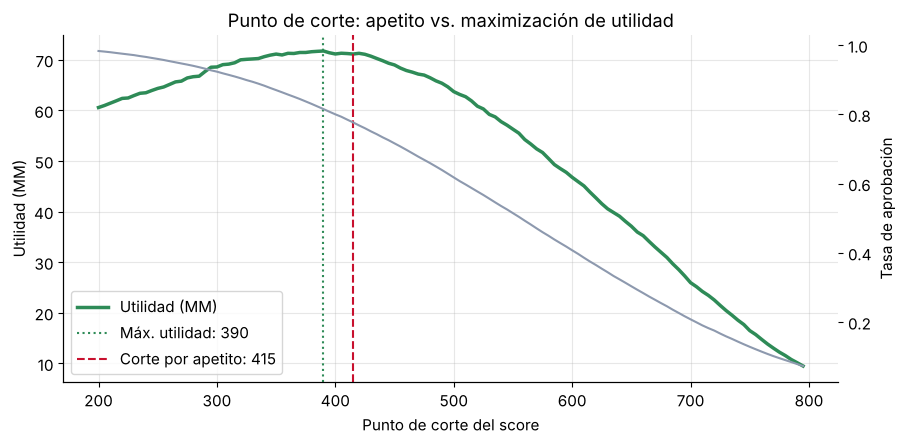

In [11]:
r, rf, cop, LGD = 0.28, 0.06, 0.07, 0.75
base["margen"] = 0.55 * base.AMT_CREDIT * (r - rf - cop)
base["perdida"] = base.TARGET * LGD * 0.80 * base.AMT_CREDIT   # pérdida realizada (ex post)
print(f"PD de equilibrio aproximada: {0.55 * (r - rf - cop) / (LGD * 0.80):.1%}")
base["contrib"] = base.margen - base.perdida

curva["utilidad_MM"] = [base.loc[base.SCORE_BURO >= c, "contrib"].sum() / 1e6 for c in cortes]
corte_util = curva.loc[curva.utilidad_MM.idxmax(), "corte"]

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(curva.corte, curva.utilidad_MM, color=VERDE, lw=2.5, label="Utilidad (MM)")
ax1.axvline(corte_util, color=VERDE, ls=":", label=f"Máx. utilidad: {corte_util:.0f}")
ax1.axvline(corte_opt, color=ROJO, ls="--", label=f"Corte por apetito: {corte_opt:.0f}")
ax2 = ax1.twinx(); ax2.plot(curva.corte, curva.tasa_aprobacion, color=GRIS, label="Aprobación"); ax2.grid(False)
ax1.set_xlabel("Punto de corte del score"); ax1.set_ylabel("Utilidad (MM)"); ax2.set_ylabel("Tasa de aprobación")
ax1.legend(loc="lower left"); ax1.set_title("Punto de corte: apetito vs. maximización de utilidad"); plt.show()

**Mensaje clave:** el corte que maximiza la utilidad **no tiene por qué coincidir** con el que dicta el apetito. Si el corte rentable implica más riesgo del tolerado, la discusión no es técnica: es de **gobierno** (capital, volatilidad de resultados, reputación, regulación). Volveremos a esto con RAROC en el Módulo 8.

## 4. Capacidad de pago: relación cuota/ingreso (RCI) y límites

,n,tasa_malos,participacion
RCI_b,,,
"(0.0, 0.1]",6270,6.32%,10.9%
"(0.1, 0.2]",14863,6.57%,25.8%
"(0.2, 0.3]",11440,7.09%,19.9%
"(0.3, 0.4]",7778,7.57%,13.5%
"(0.4, 0.5]",4506,7.75%,7.8%
"(0.5, 0.7]",5584,9.35%,9.7%
"(0.7, 10.0]",7124,13.43%,12.4%


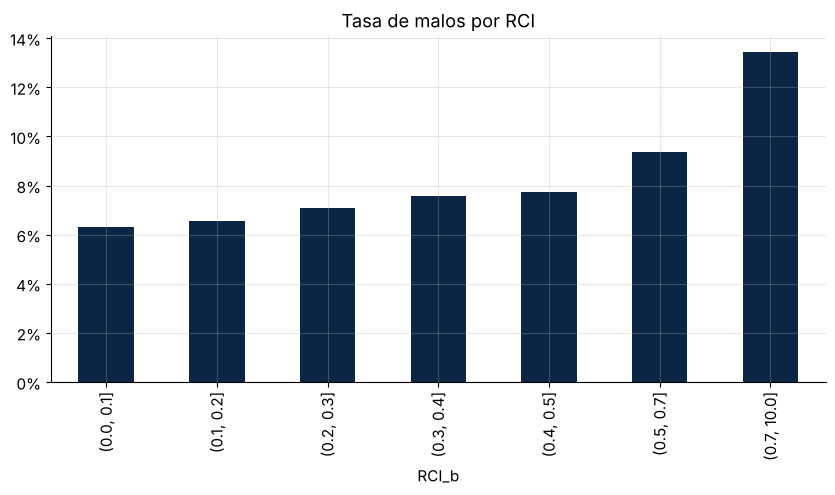

In [12]:
base["RCI_b"] = pd.cut(base.RCI, [0, .1, .2, .3, .4, .5, .7, 10])
t = base.groupby("RCI_b", observed=True).agg(n=("TARGET", "size"), tasa_malos=("TARGET", "mean"))
t["participacion"] = t.n / t.n.sum()
display(t.style.format({"tasa_malos": "{:.2%}", "participacion": "{:.1%}"}))

ax = t.tasa_malos.plot(kind="bar", color=AZUL); ax.set_title("Tasa de malos por RCI"); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); plt.show()

In [13]:
# Matriz de política: score x RCI  ->  tasa de malos y volumen
base["BANDA3"] = pd.qcut(base.SCORE_BURO, 3, labels=["Score bajo", "Score medio", "Score alto"])
base["RCI3"] = pd.cut(base.RCI, [0, .3, .5, 10], labels=["RCI<=30%", "30-50%", ">50%"])
m = base.pivot_table(index="BANDA3", columns="RCI3", values="TARGET", aggfunc=["mean", "size"], observed=True)
m["mean"].style.format("{:.2%}").background_gradient(cmap="RdYlGn_r")

RCI3,RCI<=30%,30-50%,>50%
BANDA3,,,
Score bajo,13.35%,14.41%,20.42%
Score medio,5.00%,5.99%,8.61%
Score alto,2.29%,2.43%,3.57%


**Política resultante (ejemplo para debatir):**

| | RCI <= 30 % | 30-50 % | > 50 % |
|---|---|---|---|
| **Score alto** | Aprobar | Aprobar | Aprobar con monto reducido |
| **Score medio** | Aprobar | Aprobar con monto reducido | Rechazar / excepción |
| **Score bajo** | Revisión | Rechazar | Rechazar |

Esta es la esencia de una **matriz de decisión**: combina *voluntad de pago* (score) con *capacidad de pago* (RCI).

## 5. Excepciones y *overrides*
Toda política tiene excepciones. Hay dos tipos:
- **Low-side override:** se aprueba un cliente que la política rechaza (riesgo).
- **High-side override:** se rechaza un cliente que la política aprueba (costo de oportunidad).

Simulemos que el área comercial aprueba como excepción el 15 % de los rechazados por score, con preferencia por montos altos.

In [14]:
rng = np.random.default_rng(7)
base["aprob_politica"] = base.SCORE_BURO >= corte_opt
rech = base[~base.aprob_politica]
p_exc = 0.15 * (rech.AMT_CREDIT.rank(pct=True) * 1.5)      # mayor probabilidad de excepción a mayor monto
exc_idx = rech.index[rng.random(len(rech)) < p_exc.clip(0, 1)]
base["excepcion"] = base.index.isin(exc_idx)

resumen = pd.DataFrame({
    "n": [base.aprob_politica.sum(), base.excepcion.sum()],
    "tasa_malos": [base.loc[base.aprob_politica, "TARGET"].mean(), base.loc[base.excepcion, "TARGET"].mean()],
    "monto_prom": [base.loc[base.aprob_politica, "AMT_CREDIT"].mean(), base.loc[base.excepcion, "AMT_CREDIT"].mean()],
}, index=["Aprobados por política", "Excepciones"])
display(resumen.style.format({"tasa_malos": "{:.2%}", "monto_prom": "{:,.0f}", "n": "{:,}"}))

cartera = base[base.aprob_politica | base.excepcion]
print(f"Tasa de excepciones: {base.excepcion.sum() / len(cartera):.1%} de la cartera aprobada")
print(f"Tasa de malos de la cartera total: {cartera.TARGET.mean():.2%}  (sin excepciones: {base.loc[base.aprob_politica, 'TARGET'].mean():.2%})")

,n,tasa_malos,monto_prom
Aprobados por política,"44,720",4.99%,"32,640"
Excepciones,"1,435",20.14%,"49,462"


Tasa de excepciones: 3.1% de la cartera aprobada
Tasa de malos de la cartera total: 5.46%  (sin excepciones: 4.99%)


**Gobierno de excepciones:** toda excepción debe registrarse (quién, por qué, con qué autonomía) y su **desempeño debe monitorearse aparte**. Indicadores típicos: % de excepciones sobre aprobaciones, tasa de malos de las excepciones vs. la cartera en política, y límite máximo de excepciones por canal o agencia.

## 6. Ejercicios
1. Cambia el `APETITO` a 4 % y a 6 %. ¿Cuánto volumen se gana o se pierde por cada punto de tasa de malos?
2. Agrega un filtro duro de `RCI <= 0.6`. ¿Mejora la curva de estrategia? ¿A qué costo?
3. Repite la curva de estrategia **por canal**. ¿Debería existir un corte distinto para *Retail aliado*?
4. Propón un límite de excepciones (%) y un indicador de alerta para el comité de riesgos.

---
**Conexión con el programa:** en el Módulo 3 reemplazaremos el score de buró por un *scorecard* propio (regresión logística + WoE). En el Módulo 7 la pérdida ex post se convertirá en **pérdida esperada** (PD × LGD × EAD).